<a href="https://colab.research.google.com/github/Pree-om/diabetes_prediction/blob/main/diabetes_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pickle

In [47]:
print('numpy',np.__version__)
print('pandas',pd.__version__)
print('sklearn',sklearn.__version__)

numpy 2.0.2
pandas 2.2.2
sklearn 1.6.1


In [48]:
#importing dataset
dataset = pd.read_csv('/content/diabetes.csv')
dataset

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [49]:
dataset.info() #no missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [50]:
dataset.isnull().sum() #to check missing values

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [51]:
# Replace zero values in 'Glucose' with the mean of the 'Glucose' column
dataset['Glucose'] = dataset['Glucose'].replace(0, dataset['Glucose'].mean())

# Replace zero values in 'BloodPressure' with the median of the 'BloodPressure' column
dataset['BloodPressure'] = dataset['BloodPressure'].replace(0, dataset['BloodPressure'].median())

# Replace zero values in 'BMI' with the mean of the 'BMI' column
dataset['BMI'] = dataset['BMI'].replace(0, dataset['BMI'].mean())

# Replace zero values in 'SkinThickness' with the mean of the 'SkinThickness' column
dataset['SkinThickness'] = dataset['SkinThickness'].replace(0, dataset['SkinThickness'].mean())

# Replace zero values in 'Insulin' with the mean of the 'Insulin' column
dataset['Insulin'] = dataset['Insulin'].replace(0, dataset['Insulin'].mean())


In [52]:
dataset

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35.000000,79.799479,33.6,0.627,50,1
1,1,85.0,66,29.000000,79.799479,26.6,0.351,31,0
2,8,183.0,64,20.536458,79.799479,23.3,0.672,32,1
3,1,89.0,66,23.000000,94.000000,28.1,0.167,21,0
4,0,137.0,40,35.000000,168.000000,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76,48.000000,180.000000,32.9,0.171,63,0
764,2,122.0,70,27.000000,79.799479,36.8,0.340,27,0
765,5,121.0,72,23.000000,112.000000,26.2,0.245,30,0
766,1,126.0,60,20.536458,79.799479,30.1,0.349,47,1


In [53]:
#Splitting the dependent ond independent variable
X = dataset.drop(["Outcome"], axis = 1)
y = dataset['Outcome']

In [54]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [55]:
#splitting the dataset into training and testing datasets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.33, random_state =42)

In [56]:
X_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
464,10,115.0,98,20.536458,79.799479,24.0,1.022,34
223,7,142.0,60,33.000000,190.000000,28.8,0.687,61
393,4,116.0,72,12.000000,87.000000,22.1,0.463,37
766,1,126.0,60,20.536458,79.799479,30.1,0.349,47
570,3,78.0,70,20.536458,79.799479,32.5,0.270,39
...,...,...,...,...,...,...,...,...
71,5,139.0,64,35.000000,140.000000,28.6,0.411,26
106,1,96.0,122,20.536458,79.799479,22.4,0.207,27
270,10,101.0,86,37.000000,79.799479,45.6,1.136,38
435,0,141.0,72,20.536458,79.799479,42.4,0.205,29


In [57]:
#KNN
from sklearn.neighbors import KNeighborsClassifier
traning_accuracy = []
test_accuracy = []
for n in range (1,15):
  knn = KNeighborsClassifier(n_neighbors=n)
  knn.fit(X_train, y_train)
  traning_accuracy.append(knn.score(X_train, y_train))
  test_accuracy.append(knn.score(X_test, y_test))

y_pred=knn.predict(X_test)

Text(0, 0.5, 'Accuracy')

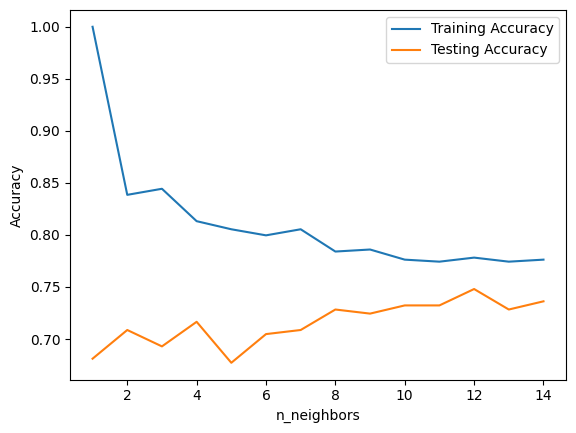

In [58]:
plt.plot(range(1,15), traning_accuracy, label = 'Training Accuracy')
plt.plot(range(1,15), test_accuracy, label = 'Testing Accuracy')
plt.legend()
plt.xlabel('n_neighbors')
plt.ylabel('Accuracy')

In [59]:
(traning_accuracy, test_accuracy)

([1.0,
  0.8385214007782101,
  0.8443579766536965,
  0.8132295719844358,
  0.8054474708171206,
  0.7996108949416343,
  0.8054474708171206,
  0.7840466926070039,
  0.7859922178988327,
  0.7762645914396887,
  0.77431906614786,
  0.7782101167315175,
  0.77431906614786,
  0.7762645914396887],
 [0.6811023622047244,
  0.7086614173228346,
  0.6929133858267716,
  0.7165354330708661,
  0.6771653543307087,
  0.7047244094488189,
  0.7086614173228346,
  0.7283464566929134,
  0.7244094488188977,
  0.7322834645669292,
  0.7322834645669292,
  0.7480314960629921,
  0.7283464566929134,
  0.7362204724409449])

In [60]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Calculate Precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# Calculate F1-Score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred)
print("ROC-AUC:", roc_auc)

Confusion Matrix:
 [[146  22]
 [ 45  41]]

Accuracy: 0.7362204724409449
Precision: 0.6507936507936508
Recall: 0.47674418604651164
F1-Score: 0.5503355704697986
ROC-AUC: 0.6728959025470653


In [61]:
# RandomForest

In [62]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(random_state=0)
dt.fit(X_train,y_train)
print(dt.score(X_train,y_train),": Training accuracy")
print(dt.score(X_test,y_test),": Testing accuracy")
y_pred=dt.predict(X_test)

1.0 : Training accuracy
0.6811023622047244 : Testing accuracy


In [63]:
from sklearn.tree import DecisionTreeClassifier
dt1=DecisionTreeClassifier(random_state=0, max_depth=9)
dt1.fit(X_train,y_train)
print(dt1.score(X_train,y_train),": Training accuracy")
print(dt1.score(X_test,y_test),": Testing accuracy")
y_pred=dt1.predict(X_test)

0.9182879377431906 : Training accuracy
0.6929133858267716 : Testing accuracy


In [64]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Calculate Precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# Calculate F1-Score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred)
print("ROC-AUC:", roc_auc)

Confusion Matrix:
 [[116  52]
 [ 26  60]]

Accuracy: 0.6929133858267716
Precision: 0.5357142857142857
Recall: 0.6976744186046512
F1-Score: 0.6060606060606061
ROC-AUC: 0.6940753045404208


In [65]:
# MLP

In [66]:
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(random_state=42)
mlp.fit(X_train, y_train)
print(mlp.score(X_train, y_train), ": Training accuracy")
print(mlp.score(X_test, y_test), ": Testing accuracy")

0.7470817120622568 : Training accuracy
0.6614173228346457 : Testing accuracy


In [67]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
mlp1 = MLPClassifier(random_state=42)
mlp1.fit(X_train, y_train)
y_pred=mlp1.predict(X_test)
print(mlp1.score(X_train, y_train), ": Training accuracy")
print(mlp1.score(X_test, y_test), ": Testing accuracy")

0.830739299610895 : Training accuracy
0.7322834645669292 : Testing accuracy


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [68]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Calculate Precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# Calculate F1-Score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred)
print("ROC-AUC:", roc_auc)

Confusion Matrix:
 [[134  34]
 [ 34  52]]

Accuracy: 0.7322834645669292
Precision: 0.6046511627906976
Recall: 0.6046511627906976
F1-Score: 0.6046511627906976
ROC-AUC: 0.7011351052048727


In [69]:
# SVM

In [70]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC
# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
# Train SVM model
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train, y_train)
# Make predictions
y_pred = svm_model.predict(X_test)
# Evaluate the model
train_accuracy = svm_model.score(X_train, y_train)
test_accuracy = svm_model.score(X_test, y_test)
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.8366
Testing Accuracy: 0.7402


In [71]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)

# Calculate Precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# Calculate F1-Score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_pred)
print("ROC-AUC:", roc_auc)

Confusion Matrix:
 [[140  28]
 [ 38  48]]

Accuracy: 0.7401574803149606
Precision: 0.631578947368421
Recall: 0.5581395348837209
F1-Score: 0.5925925925925926
ROC-AUC: 0.6957364341085271


In [72]:
with open('model.pkl', 'wb') as file:
    pickle.dump(svm_model, file)